In [ ]:
from aguirre.config import DB_CACHE_DIR
from aguirre.extern.dbaasp import hole_seite

d = hole_seite(limit=1, offset=0, roh_pfad=DB_CACHE_DIR / "dbaasp" / "probe.json")

print(list(d.keys()))
print({k: v for k, v in d.items() if not isinstance(v, (list, dict))})

In [ ]:
eintraege = d["data"]
print(len(eintraege), list(eintraege[0].keys()))

#### Test für Identifier

In [ ]:
from aguirre.config import DB_CACHE_DIR
from aguirre.extern import dbaasp

# 1. Detail-Diagnose: welcher Identifier, wie heisst das Aktivitaetsfeld
d = dbaasp.hole_seite(limit=1)
e = d["data"][0]
print(e["id"], e["dbaaspId"], e["complexity"], e["synthesisType"])
print(e["nTerminus"], e["cTerminus"], e["NTerminus"], e["CTerminus"])

det = dbaasp.hole_detail(e["id"], roh_pfad=DB_CACHE_DIR / "dbaasp" / "probe_detail.json")
print(list(det.keys()))


# 2. Stufe 1 komplett -- 128 Seiten, rund eine Minute
dbaasp.hole_liste()
df = dbaasp.lade_liste()
print(df["complexity"].value_counts())
print(df["cTerminus"].value_counts(dropna=False).head())
print(df["sequenceLength"].describe())

#### Spezies-Filter-Test
und Speziesliste

In [ ]:
from aguirre.extern import dbaasp

# 1. Traegt der Spezies-Filter? EIN Request.
p = dbaasp.hole_seite(limit=1, zusatz={"targetSpecies.value": "Escherichia coli"})
print(p["totalCount"])          # erwartet: deutlich unter 25542, aber > 0

In [ ]:
# 2. Sieben gefilterte Listen holen und vereinigen
df = dbaasp.hole_spezies_listen()

# 3. nTerminus ansehen -- Default filtert ihn NICHT
print(df["nTerminus"].value_counts(dropna=False).head(10))
print(df["synthesisType"].value_counts())

# 4. Vorfilter mit Bericht pro Stufe
kand = dbaasp.filtere_kandidaten(df)

# 5. Stufe 2 -- Laufzeit wird mit Restschätzung ausgegeben
dbaasp.hole_details(kand["id"].tolist())

#### Daten in CSV-Long-Format

In [1]:
%load_ext autoreload
%autoreload 2
from aguirre.extern import dbaasp

df = dbaasp.parse_messungen()     # nur MIC, schreibt dbaasp_messungen.csv
df.head(3)

  ... 1000/4560 Dateien, 10352 Zeilen
  ... 2000/4560 Dateien, 19435 Zeilen
  ... 3000/4560 Dateien, 27388 Zeilen
  ... 4000/4560 Dateien, 34868 Zeilen

40725 Messungen, 4195 Peptide
zensur:        {'=': 29614, '>': 7399, '~': 3214, '<': 423, '?': 75}
mic_ug_ml da:  40725
mic_um da:     35695
MW bekannt:    35695 Zeilen, 3633 Peptide (davon aus DBAASP: 1830)
MW-Kontrolle:  relative Abweichung DBAASP gegen Sequenz, Median 0.11%, 90%-Quantil 0.28%
geschrieben:   /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/data_tracked/extern/dbaasp_messungen.csv


,peptide_id,dbaasp_id,sequence,sequence_length,complexity,synthesis_type,n_terminus,c_terminus,unusual_aa,species,...,mic_ug_ml,mic_um,zensur,concentration_raw,unit_raw,mw,mw_dbaasp,mw_sequenz,reference,activity_id
0,10,DBAASPS_10,LFIFFF,6,Monomer,Synthetic,NaN,AMD,,Staphylococcus aureus,...,15.0,18.006327,~,11-15,µg/ml,833.0405,NaN,833.0405,1,8
1,10,DBAASPS_10,LFIFFF,6,Monomer,Synthetic,NaN,AMD,,Streptococcus sanguinis,...,5.0,6.002109,~,3-5,µg/ml,833.0405,NaN,833.0405,1,5555
2,1003,DBAASPR_1003,GWGSFFKKAAHVGKHVGKAALTHYL,25,Monomer,Ribosomal,NaN,NaN,,Escherichia coli,...,3.1,1.143419,=,3.1,µg/ml,2711.1675,NaN,2711.1675,1,5934


In [2]:
import pandas as pd

print("MW pro Rest:")
print((df["mw_dbaasp"] / df["sequence_length"]).describe())

roh = pd.to_numeric(df["concentration_raw"], errors="coerce")
m = df["unit_raw"].eq("µg/ml") & roh.notna()
print("\nCheck 2 (muss 0.0 sein):", (df.loc[m, "mic_ug_ml"] - roh[m]).abs().max())

MW pro Rest:
count    19750.000000
mean       121.841467
std         16.589374
min         45.898331
25%        110.942000
50%        118.368788
75%        128.168333
max        204.256000
dtype: float64

Check 2 (muss 0.0 sein): 0.0


#### DRAMP - CSV schreiben + gefilterte CSV für Prädiktorenvergleich

In [2]:
from aguirre.extern import dramp

df = dramp.lade_general()
dramp.baue_novelty_csv(df)
dramp.baue_vergleich_csv(df)

[novelty] 12784 Eintraege -> 12784 mit Sequenz -> 11485 eindeutig
[novelty] geschrieben: /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/data_tracked/extern/dramp_novelty.csv
[vergleich] 12784 Eintraege
  nach linear             6878
  nach stereo_L           6297
  nach nterm_frei         5073
  nach cterm_frei_amid    4988
  nach kanonisch          4305
  3448 gefilterte Eintraege ohne verwertbare Messung (keine Zielspezies, unbekannte Einheit, oder mehrdeutig)

[vergleich] 2808 Messungen, 857 Peptide
  je Spezies:  {'Escherichia coli': 1094, 'Staphylococcus aureus': 943, 'Pseudomonas aeruginosa': 771}
  zensur:      {'=': 2422, '>': 266, '~': 91, '<': 29}
  mic_um da:   2808
[vergleich] geschrieben: /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/data_tracked/extern/dramp_vergleich.csv


,dramp_id,sequence,sequence_length,n_terminus,c_terminus,stereochemistry,topologie,mw_sequenz,pubmed_id,species,strain,organism_raw,zensur,mic_ug_ml,mic_um,einheit_roh,wert_roh
0,DRAMP00089,TTKNYGNGVCNSVNWCQCGNVWASCNLATGCAAWLCKLA,39,Free,Free,L,Linear,4125.7147,18293921,Escherichia coli,O157:H7,"), Yersinia enterocolitica, Yersinia pseudotub...",<,1.600000,0.387812,µg/ml,1.6
1,DRAMP00089,TTKNYGNGVCNSVNWCQCGNVWASCNLATGCAAWLCKLA,39,Free,Free,L,Linear,4125.7147,18293921,Staphylococcus aureus,,);##Gram-positive bacteria: Staphylococcus aur...,~,0.400000,0.096953,µg/ml,0.2-0.8
2,DRAMP00107,TNYGNGVGVPDAIMAGIIKLIFIFNIRQGYNFGKKAT,37,Free,Free,L,Linear,4002.6897,21378051,Escherichia coli,HB 101,"), Escherichia coli HB 101 (",=,0.190000,0.047468,ug/ml,0.19
3,DRAMP00107,TNYGNGVGVPDAIMAGIIKLIFIFNIRQGYNFGKKAT,37,Free,Free,L,Linear,4002.6897,21378051,Escherichia coli,600,"), E. coli-600 (",=,0.190000,0.047468,ug/ml,0.19
4,DRAMP00107,TNYGNGVGVPDAIMAGIIKLIFIFNIRQGYNFGKKAT,37,Free,Free,L,Linear,4002.6897,21378051,Escherichia coli,O157:H7 Y-63,"), E. coli O157:H7 Y-63 (",=,0.190000,0.047468,ug/ml,0.19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2803,DRAMP39399,GIGAVLKVLTTGLKWKLFKKIEKVGQ,26,Free,Free,L,Linear,2855.5467,2689223,Pseudomonas aeruginosa,,);Pseudomonas aeruginosa(,=,14.277734,5.000000,µM,5
2804,DRAMP39399,GIGAVLKVLTTGLKWKLFKKIEKVGQ,26,Free,Free,L,Linear,2855.5467,2689223,Staphylococcus aureus,,);Staphylococcus aureus(,=,14.277734,5.000000,µM,5
2805,DRAMP39400,LISWIKRKRQQKWKLFKKIEKVGQ,24,Free,Free,L,Linear,3069.7793,2689223,Escherichia coli,K12,[Ref.2689223]Gram-negative bacteria:Escherichi...,=,2.148846,0.700000,µM,0.7
2806,DRAMP39400,LISWIKRKRQQKWKLFKKIEKVGQ,24,Free,Free,L,Linear,3069.7793,2689223,Pseudomonas aeruginosa,,);Pseudomonas aeruginosa(,=,24.558234,8.000000,µM,8


#### Novelty-CSV aus APD6

In [1]:
from aguirre.extern import apd

df = apd.baue_novelty_csv()
df.head()

[apd] Quelle: /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/data/cache/DBs/apd6/naturalAMPs_APD2024a.fasta
[apd] 3307 Header gelesen -> 1 ohne APD-Kennung verworfen -> 3306 mit Sequenz -> 3306 eindeutig
[apd] nicht-kanonische Sequenzen: 0 (bleiben drin)
[apd] Laenge: Median 29, min 2, max 183
[apd] geschrieben: /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/data_tracked/extern/apd_novelty.csv


,apd_id,sequence,sequence_length
0,AP00001,GLWSKIKEVGKEAAKAAAKAAGKAALGAVSEAV,33
1,AP00002,YVPLPNVPQPGRRPFPTFPGQGPFNPKIKWPQGY,34
2,AP00003,DGVKLCDVPSGTWSGHCGSSSKCSQQCKDREHFAYGGACHYQFPSV...,54
3,AP00004,NLCERASLTWTGNCGNTGHCDTQCRNWESAKHGACHKRGNWKCFCYFDC,49
4,AP00005,VFIDILDKVENAIHNAAQVGIGFAKPFEKLINPK,34


#### Novelty-Datensatz mit patent_amps aus dramp bauen:

In [1]:
from aguirre.config import DB_EXTERN_DIR
from aguirre.extern import dramp, referenz

dramp.baue_novelty_csv(df=dramp.lade_patent(),
                       out_pfad=DB_EXTERN_DIR / "dramp_patent_novelty.csv")

bekannt = referenz.baue_novelty_referenz(mit_patent=True)

[novelty] 18715 Eintraege -> 18715 mit Sequenz -> 16586 eindeutig
[novelty] geschrieben: /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/data_tracked/extern/dramp_patent_novelty.csv
[liste] 128 Seiten, 25542 Zeilen, 25542 eindeutige ids, totalCount 25542
[referenz] dbaasp: 25377 roh -> 20178 eindeutig
[referenz] dramp: 11485 roh -> 11485 eindeutig
[referenz] apd: 3306 roh -> 3306 eindeutig
[referenz] patent: 16586 roh -> 16586 eindeutig
[referenz] 56754 Zeilen aus 3 Quellen -> 41791 eindeutige Sequenzen (14963 Ueberschneidungen entfernt)
[referenz] Quellenverteilung:
quellen
patent                     14938
dbaasp                     13157
dramp                       5442
dbaasp|dramp                3672
apd|dbaasp|dramp            1274
dbaasp|patent                969
apd|dbaasp                   632
apd                          554
apd|dramp                    474
apd|dbaasp|dramp|patent      232
dbaasp|dramp|patent          200
dramp|patent                 107
a

In [1]:
from aguirre.extern import referenz
decke = referenz.baue_real_amps_test(ausschluss=("train", "val"))

[decke] Torres-Testsplit: 1938
[decke] ausgeschlossen (train, val): 17446 Sequenzen
[decke] aus amps_bekannt neu dazu: 22479 von 41791
[decke] gesamt: 24417 eindeutige Sequenzen
[decke] davon kanonisch: 19672 (80.6%) -- 4745 nicht-kanonisch, bleiben in der Datei, werden aber im Panel nicht bewertet
[decke] Laenge: Median 16, min 1, max 190
[decke] geschrieben: /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/splits/real_amps_test.fasta (+ .csv)


### Sequenzfragmente aus UniProt Proteine (zytoplasmatische Proteine)

In [1]:
from aguirre.config import DB_CACHE_DIR, DB_EXTERN_DIR, SPLIT_DIR
from aguirre.extern import uniprot, zufall

UNIPROT_FASTA = DB_CACHE_DIR / "uniprot" / "uniprotkb_reviewed_true_AND_cc_scl_term_2026_11_25.fasta.gz"

lower = uniprot.baue_uniprot_boden(
    proteine_fasta=UNIPROT_FASTA,
    n=10000,
    referenz_fasta=DB_EXTERN_DIR / "amps_bekannt.fasta",
)

[uniprot] 149816 Proteine gelesen
[uniprot] uebersprungen: 0 zu kurz, 4 ohne cysteinfreies Fenster der gezogenen Laenge
[uniprot] 10000 Fragmente -> 9999 nach Deduplizierung
[uniprot] WARNUNG: nur 9999 von 10000 erreicht. Mehr Proteine laden oder rand verkleinern.
[uniprot] Laenge: Median 15, min 5, max 50
[uniprot] ueberhaupt ein Treffer gegen amps_bekannt.fasta: 5 von 9999
[uniprot]   max_ident_bekannt > 0.4: 5
[uniprot]   max_ident_bekannt > 0.5: 5
[uniprot]   max_ident_bekannt > 0.6: 5
[schreiben] /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/splits/uniprot_lower.fasta (+ .csv)


In [2]:
rand = zufall.baue_random_len(n=10000)

[zufall] Komposition: uniform
[zufall] 10000 gezogen -> 10000 nach Deduplizierung
[zufall] Laenge: Median 15, min 5, max 50
[schreiben] /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/splits/random_len.fasta (+ .csv)


### ANIA-VS-APEX

In [1]:
from pathlib import Path
from aguirre.config import EVAL_SET_DIR
from aguirre.extern import tool_val

tv = tool_val.baue_tool_val()
fasta = tool_val.schreibe_ania_fasta(tv, EVAL_SET_DIR / "tool_val_ania.fasta")
tv.head()

[tool_val] 43533 Messungen roh
[tool_val]   -> 21756 nach Speziesfilter
[tool_val]   -> 17337 nach kanonisch
[tool_val]   -> 16835 nach Terminifilter
[tool_val]   -> 16808 nach Laenge 5-50
[tool_val]   -> 16803 mit MIC-Wert
[tool_val] aggregiert: 8193 Zeilen, 3491 eindeutige Sequenzen
[tool_val] je Spezies: {'Escherichia coli': 3112, 'Staphylococcus aureus': 2955, 'Pseudomonas aeruginosa': 2126}
[tool_val] Zensur: {'=': 6442, '>': 1487, '~': 222, '<': 42}
[tool_val] amidiert: 4566 | in Torres' Trainingsdaten: 4211
[tool_val] Baender: {'niedrig (<=8 uM)': 3420, 'mittel (8-64 uM)': 3366, 'hoch (>64 uM)': 1407}
[tool_val] Messrauschen (max/min je Peptid-Spezies, n=6442): Median 1.0x, 90. Perzentil 7.3x
[tool_val] geschrieben: /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/data_tracked/eval_sets/tool_val.csv
[tool_val] 3491 eindeutige Sequenzen -> /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/data_tracked/eval_sets/tool_val_ania.fasta


,sequence,species,mic_mess,zensur,n_mess,n_unzensiert,spanne,quellen,c_amidiert,sequence_length,mic_band,in_torres_train
0,AAGKGLVSNLLEK,Escherichia coli,24.6,=,1,1,1.0,dramp,True,13,mittel (8-64 uM),True
1,AAGKGLVSNLLEK,Staphylococcus aureus,49.0,=,1,1,1.0,dramp,True,13,mittel (8-64 uM),True
2,AAGKVLKLLKKLL,Staphylococcus aureus,23.0,=,1,1,1.0,dbaasp,False,13,mittel (8-64 uM),True
3,AAHCIALRKGYK,Escherichia coli,30.0,>,1,0,NaN,dbaasp,True,12,mittel (8-64 uM),False
4,AAHCIALRKGYK,Pseudomonas aeruginosa,30.0,=,1,1,1.0,dbaasp,True,12,mittel (8-64 uM),False


In [2]:
tv = tool_val.ergaenze_apex(tv)
print(tv[["sequence", "species", "mic_mess", "mic_apex"]].head())

[tool_val] APEX: 8193 von 8193 Zeilen
        sequence                 species  mic_mess    mic_apex
0  AAGKGLVSNLLEK        Escherichia coli      24.6  480.599657
1  AAGKGLVSNLLEK   Staphylococcus aureus      49.0  498.399686
2  AAGKVLKLLKKLL   Staphylococcus aureus      23.0  233.685492
3   AAHCIALRKGYK        Escherichia coli      30.0  413.520737
4   AAHCIALRKGYK  Pseudomonas aeruginosa      30.0  435.554658


In [3]:
tv = tool_val.ergaenze_ania(tv, EVAL_SET_DIR / "ania_preds.csv")
tv.to_csv(EVAL_SET_DIR / "tool_val_vorhersagen.csv", index=False)
print(tv[["mic_apex", "mic_ania"]].notna().sum())

[tool_val] ANIA: 8193 von 8193 Zeilen, 10**x zurueckgerechnet
[tool_val]   MIC [µM]: Median 7.98, min 0.026, max 3076
mic_apex    8193
mic_ania    8193
dtype: int64


In [4]:
import numpy as np

s = tv["spanne"].dropna()
print(f"Peptid-Spezies-Paare mit mehr als einer Messung: {len(s)}")
print(f"Spanne max/min: Median {s.median():.1f}x, 75. Perzentil {s.quantile(.75):.1f}x")
print(f"-> untere Schranke für sigma: ca. {np.log10(s.median())/2:.2f} log10-Einheiten")

Peptid-Spezies-Paare mit mehr als einer Messung: 6442
Spanne max/min: Median 1.0x, 75. Perzentil 2.0x
-> untere Schranke für sigma: ca. 0.00 log10-Einheiten


In [5]:
from aguirre.config import PROJECT_ROOT, RESULTS_DIR

ABB = PROJECT_ROOT / "Ausarbeitung" / "abbildungen"

tab = tool_val.bayes_tabelle(tv, out_csv=RESULTS_DIR / "toolval_bayes.csv")
tab_rein = tool_val.bayes_tabelle(tv, nur_unmodifiziert=True,
                                  out_csv=RESULTS_DIR / "toolval_bayes_unmodifiziert.csv")
display(tab)
display(tab_rein)

[tool_val] geschrieben: /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/results/toolval_bayes.csv
[tool_val] geschrieben: /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/results/toolval_bayes_unmodifiziert.csv


,werkzeug,species,n,n_zensiert,treffer_zensiert,faktor,hdi89_unten,hdi89_oben,p_ueberschaetzt,spearman,r_vs_mess
0,apex,Escherichia coli,2588,510,0.825,14.80,14.12,15.58,1.000,0.28,-0.73
1,apex,Staphylococcus aureus,2355,588,0.920,31.29,30.00,32.80,1.000,0.18,-0.88
2,apex,Pseudomonas aeruginosa,1721,389,0.877,15.19,14.39,16.10,1.000,0.19,-0.82
3,ania,Escherichia coli,2588,510,0.196,0.76,0.74,0.79,0.000,0.71,-0.29
4,ania,Staphylococcus aureus,2355,588,0.362,1.00,0.97,1.04,0.519,0.54,-0.54
5,ania,Pseudomonas aeruginosa,1721,389,0.139,0.75,0.72,0.78,0.000,0.67,-0.32


,werkzeug,species,n,n_zensiert,treffer_zensiert,faktor,hdi89_unten,hdi89_oben,p_ueberschaetzt,spearman,r_vs_mess
0,apex,Escherichia coli,1192,254,0.854,20.04,18.49,21.80,1.000,0.28,-0.78
1,apex,Staphylococcus aureus,983,318,0.912,39.45,36.52,42.81,1.000,0.10,-0.94
2,apex,Pseudomonas aeruginosa,681,173,0.925,20.77,18.75,23.13,1.000,0.11,-0.87
3,ania,Escherichia coli,1192,254,0.197,0.71,0.68,0.75,0.000,0.73,-0.30
4,ania,Staphylococcus aureus,983,318,0.324,0.98,0.92,1.05,0.357,0.53,-0.60
5,ania,Pseudomonas aeruginosa,681,173,0.116,0.71,0.67,0.77,0.000,0.70,-0.34


[tool_val] Boxplot: 1529 zensierte von 8193 Zeilen nicht dargestellt (Schranke statt Messwert)
[tool_val] geschrieben: /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/results/toolval_baender.png (400 dpi)
[tool_val] geschrieben: /Users/paulmedebach/Documents/Projekte/FuE_Masterarbeit/wrath_of_god/results/toolval_scatter.png (400 dpi)


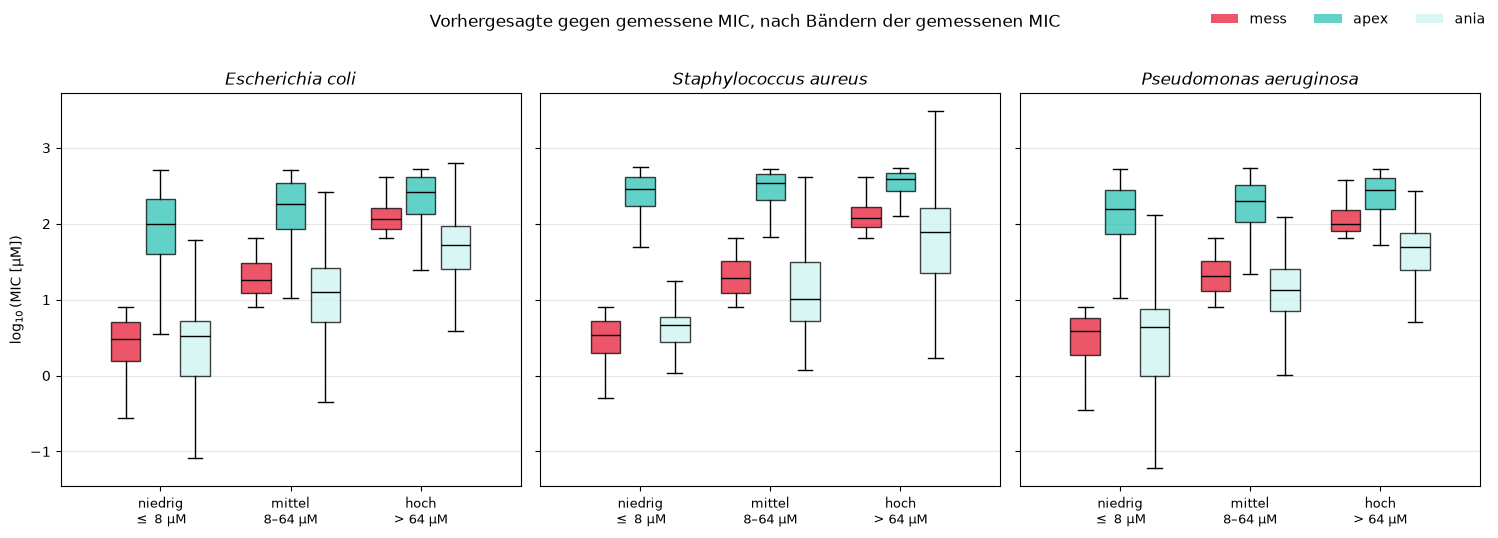

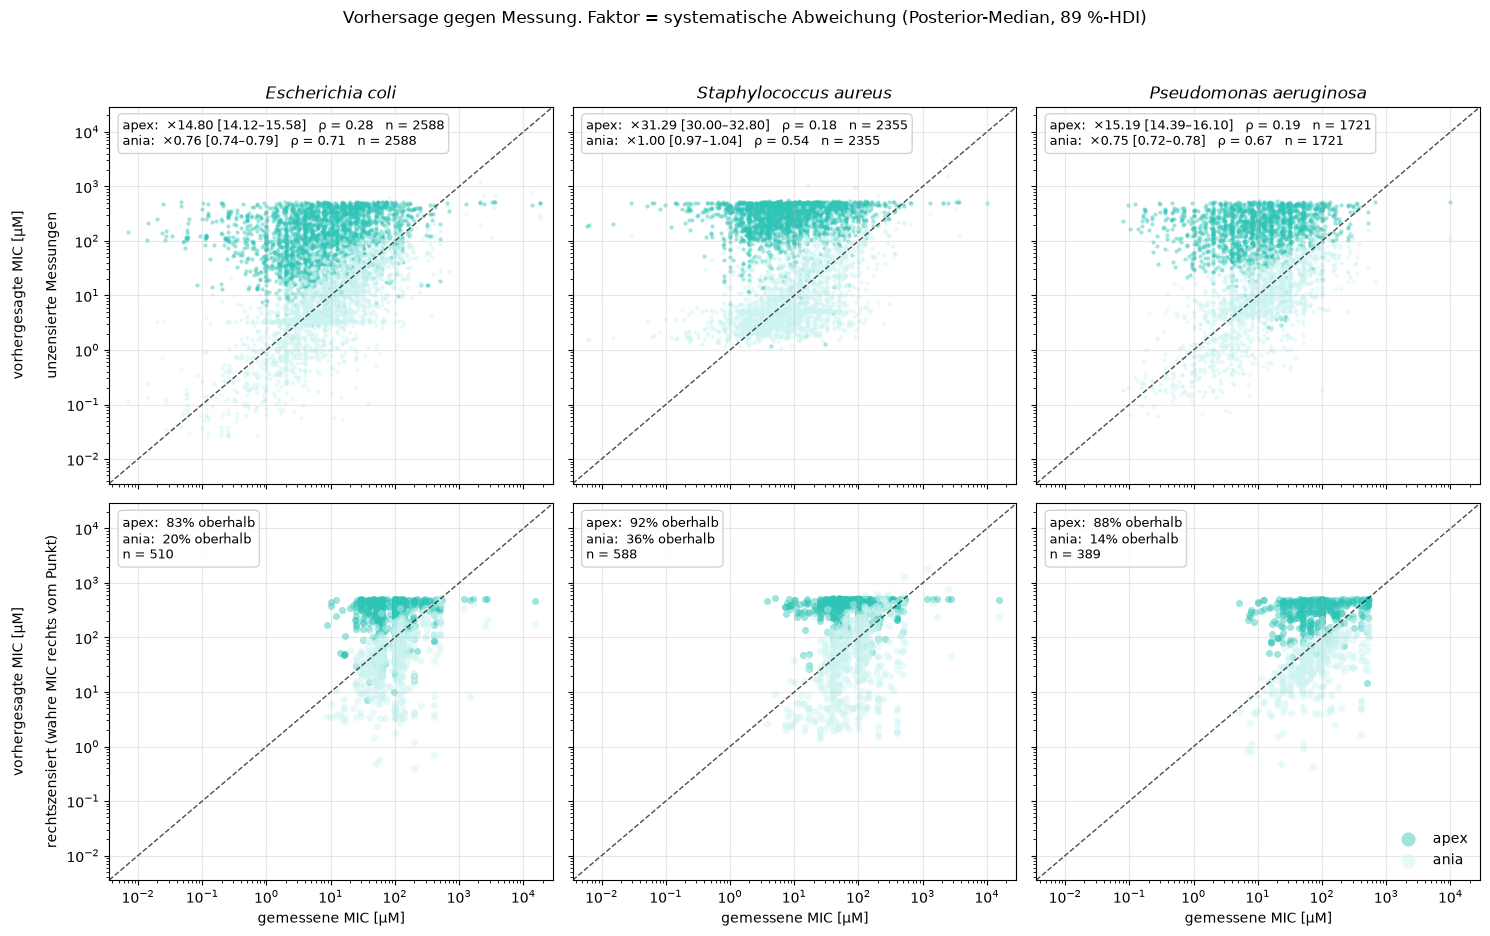

In [6]:
from aguirre.config import RESULTS_DIR
ABB = RESULTS_DIR
fig1 = tool_val.plot_baender(tv, out=ABB / "toolval_baender.png")
fig2 = tool_val.plot_scatter(tv, out=ABB / "toolval_scatter.png")